# 00 · Intraday trials, net of costs

Four published intraday effects, run through `tactical-cube` on 5-minute bars since 2004 with
realistic execution: decisions at a bar's end, fills from the next bar at its VWAP (or in the
official auctions), a 10% cap on each bar's volume, and costs for $1M of capital (time-of-day
half-spreads, square-root impact, IB per-share commission, borrow on overnight shorts).
Parameters: `configs/trials.toml`. Strategies: `src/assimilation_trials`.

1. intraday momentum on SPY (Gao, Han, Li and Zhou 2018)
2. overnight vs intraday holding of SPY
3. opening range breakout on SPY and QQQ
4. first-half-hour reversal across the 500 largest stocks
5. all four side by side

In [1]:
import matplotlib.pyplot as plt
import polars as pl
from assimilation_trials import breakout, config, momentum, overnight, reversal, stats_by_period
from tactical_cube import Cube, IntradayCosts

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(150)
cfg = config()
C = cfg["common"]
costs = IntradayCosts(aum=C["aum"])
cube = Cube()
results = {}

def show(bt):
    s = bt.summary().filter(pl.col("series").is_in(["gross", "net"]))
    return s.select("series", "ann_return", "ann_vol", "sharpe", "t_stat", "max_drawdown", "turnover_per_year", "cost_drag")

def growth(bts: dict, title: str):
    fig, ax = plt.subplots()
    for name, bt in bts.items():
        d = bt.daily
        ax.plot(d["date"], (1 + d["gross"]).cum_prod(), label=f"{name} gross", lw=1)
        ax.plot(d["date"], (1 + d["net"]).cum_prod(), label=f"{name} net", lw=1, ls="--")
    ax.set_yscale("log")
    ax.set_title(title)
    ax.legend()
    plt.show()

## 1 · Intraday momentum on SPY

The return from the previous close to 10:00 sets the side for the last half hour: long if it
was up, short if down. Enter on the bar after 15:30 (VWAP of 15:30-15:35), exit in the closing
auction. Two round trips of the whole capital a day.

In [2]:
m = cfg["momentum"]
bt = cube.run(momentum(m["ticker"], m["enter_minutes_to_close"]), C["start"], C["end"], tickers=[m["ticker"]],
              freq=C["freq"], features=["gap", "ret_open"], costs=costs)
results["momentum (SPY)"] = bt
print(f"{bt.daily.height} days in {bt.settings['seconds']} s; look-ahead checked on {bt.settings['lookahead_checked_days']} days")
show(bt)

5724 days in 44.5 s; look-ahead checked on 2 days


series,ann_return,ann_vol,sharpe,t_stat,max_drawdown,turnover_per_year,cost_drag
str,f64,f64,f64,f64,f64,f64,f64
"""net""",-0.037895,0.055154,-0.672844,-3.206743,-0.585273,503.989156,0.054766
"""gross""",0.016871,0.05517,0.33079,1.576527,-0.166339,null,null


In [3]:
stats_by_period(bt.daily)

period,days,gross_ann,net_ann,net_sharpe,net_t
str,i64,f64,f64,f64,f64
"""2000-2004""",249,-0.006756,-0.087062,-2.399861,-2.385533
"""2005-2009""",1250,0.04093,-0.029768,-0.349754,-0.778963
"""2010-2014""",1252,0.035534,-0.0207,-0.511952,-1.141119
"""2015-2019""",1256,-0.000129,-0.047005,-1.457172,-3.25316
"""2020-2024""",1258,0.004303,-0.044435,-0.77012,-1.720673
"""2025-2029""",459,0.011422,-0.027615,-0.840843,-1.134804


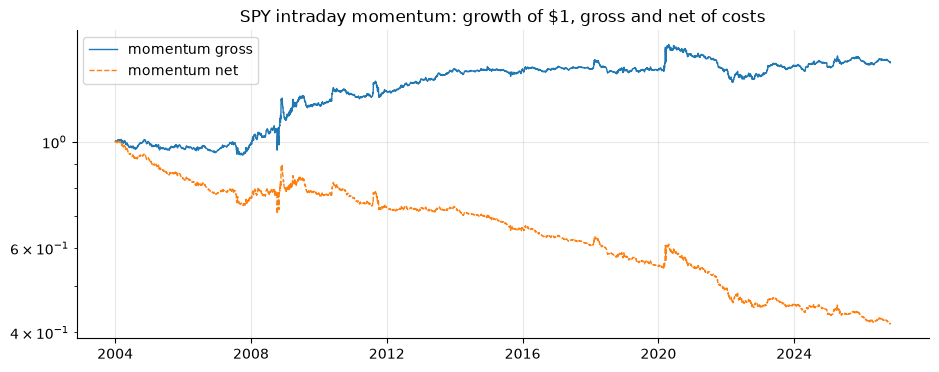

kind,fills,spread_bps,impact_bps,commission_bps,slippage_bps,participation,max_participation,wait_bars
str,u32,f64,f64,f64,f64,f64,f64,f64
"""bar""",5725,0.500064,0.662136,0.186287,-0.260262,0.005503,0.1,0.000175
"""close_auction""",5724,0.0,0.662098,0.186283,0.0,null,null,null


In [4]:
growth({"momentum": bt}, "SPY intraday momentum: growth of $1, gross and net of costs")
bt.fill_stats()

## 2 · Overnight vs intraday holding

Buy SPY in the closing auction and sell in the next opening auction (overnight), or the reverse
(intraday). Both trade only in the auctions, so the costs are commission and impact, no spread.

In [5]:
o = cfg["overnight"]
for hold in ("overnight", "intraday"):
    results[f"{hold} (SPY)"] = cube.run(overnight(o["ticker"], hold, o["decide_minutes_to_close"]), C["start"], C["end"],
                                        tickers=[o["ticker"]], freq=C["freq"], flat_by=None, costs=costs)
pl.concat([show(results[f"{h} (SPY)"]).with_columns(hold=pl.lit(h)) for h in ("overnight", "intraday")]).select("hold", pl.exclude("hold"))

hold,series,ann_return,ann_vol,sharpe,t_stat,max_drawdown,turnover_per_year,cost_drag
str,str,f64,f64,f64,f64,f64,f64,f64
"""overnight""","""net""",0.034117,0.110801,0.358574,1.711929,-0.329955,503.978526,0.045179
"""overnight""","""gross""",0.079297,0.1108,0.744576,3.554808,-0.29871,null,null
"""intraday""","""net""",-0.017405,0.14442,-0.04932,-0.235465,-0.581033,504.017021,0.042939
"""intraday""","""gross""",0.025533,0.144454,0.246801,1.178292,-0.446777,null,null


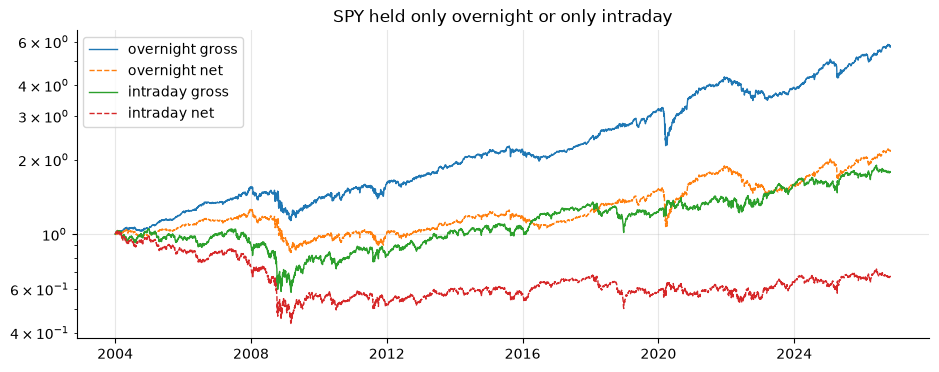

In [6]:
growth({h: results[f"{h} (SPY)"] for h in ("overnight", "intraday")}, "SPY held only overnight or only intraday")

## 3 · Opening range breakout on SPY and QQQ

After the first 30 minutes, the first 5-minute close above the range goes long and below it goes
short, half the capital per name, held to the closing auction.

In [7]:
b = cfg["breakout"]
bt = cube.run(breakout(tuple(b["tickers"]), b["or_minutes"]), C["start"], C["end"], tickers=b["tickers"],
              freq=C["freq"], features=["or_break"], or_minutes=b["or_minutes"], costs=costs)
results["breakout (SPY, QQQ)"] = bt
show(bt)

series,ann_return,ann_vol,sharpe,t_stat,max_drawdown,turnover_per_year,cost_drag
str,f64,f64,f64,f64,f64,f64,f64
"""net""",-0.069986,0.1049,-0.638921,-3.042939,-0.861743,430.459854,0.050113
"""gross""",-0.019873,0.104497,-0.139667,-0.665181,-0.69303,null,null


In [8]:
rt = bt.round_trips()
print(f"{rt.height} round trips, {rt['net'].gt(0).mean():.1%} profitable after costs, held {rt['minutes'].mean():.0f} min on average")
stats_by_period(bt.daily)

9761 round trips, 48.5% profitable after costs, held 317 min on average


period,days,gross_ann,net_ann,net_sharpe,net_t
str,i64,f64,f64,f64,f64
"""2000-2004""",251,-0.062989,-0.154758,-1.621382,-1.618162
"""2005-2009""",1248,0.032784,0.003871,0.045377,0.100981
"""2010-2014""",1251,-0.033661,-0.103164,-1.119631,-2.494613
"""2015-2019""",1253,-0.048252,-0.107438,-1.096642,-2.445344
"""2020-2024""",1255,0.001438,-0.048059,-0.348827,-0.778453
"""2025-2029""",458,-0.016947,-0.054798,-0.521072,-0.702474


## 4 · First-half-hour reversal across the top 500

At 10:00, buy the tenth of vinculum's 500 largest companies that fell most since the open and
short the tenth that rose most, half the capital each side, and close everything in the closing
auction. The universe is ranked at the previous month end, so it is known before the open.
Names that traded under $1M between the open and 10:00 are left out: a few ADRs in the top 500
trade mostly at home.

In [9]:
r = cfg["reversal"]
bt = cube.run(reversal(r["at_minutes"], r["fraction"], min_dollar_volume=r["min_dollar_volume"]), r["start"], C["end"], top=r["top"], freq=C["freq"],
              features=["ret_open"], costs=costs)
results["reversal (top 500)"] = bt
print(f"{bt.daily.height} days in {bt.settings['seconds']} s")
show(bt)

4233 days in 499.4 s


series,ann_return,ann_vol,sharpe,t_stat,max_drawdown,turnover_per_year,cost_drag
str,f64,f64,f64,f64,f64,f64,f64
"""net""",-0.142753,0.052237,-2.921625,-11.974249,-0.925364,504.102407,0.163637
"""gross""",0.020884,0.052195,0.422098,1.729964,-0.179878,null,null


In [10]:
stats_by_period(bt.daily)

period,days,gross_ann,net_ann,net_sharpe,net_t
str,i64,f64,f64,f64,f64
"""2010-2014""",1258,0.010791,-0.202144,-5.751946,-12.851531
"""2015-2019""",1258,0.054994,-0.113425,-2.707705,-6.049806
"""2020-2024""",1258,0.006284,-0.155274,-2.320006,-5.183573
"""2025-2029""",459,0.005656,-0.117014,-1.71307,-2.311965


In [11]:
bt.fill_stats()

kind,fills,spread_bps,impact_bps,commission_bps,slippage_bps,participation,max_participation,wait_bars
str,u32,f64,f64,f64,f64,f64,f64,f64
"""bar""",411113,2.234855,1.552774,0.828879,2.407833,0.006269,0.1,0.009105
"""close_auction""",409044,0.0,1.532036,0.818268,0.0,null,null,null


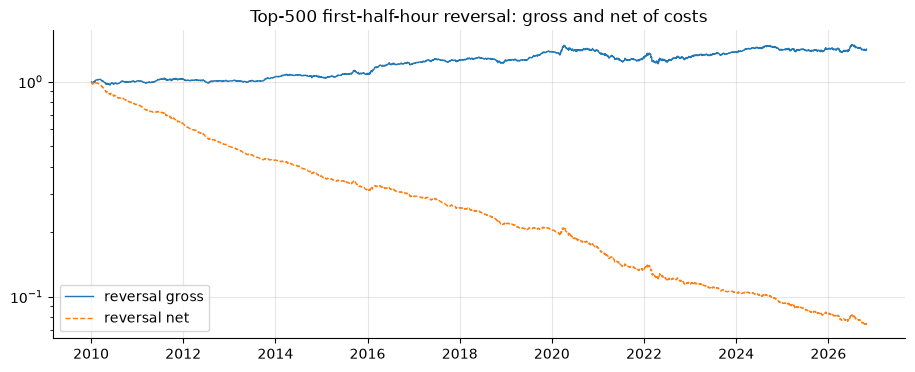

In [12]:
growth({"reversal": bt}, "Top-500 first-half-hour reversal: gross and net of costs")

## 5 · Side by side

`breakeven_bps` is the gross return per unit traded: the all-in cost per trade at which the
strategy would earn nothing. `cost_bps` is what the cost model charged.

In [13]:
rows = []
for name, bt in results.items():
    s = bt.summary()
    g, n = s.filter(pl.col("series") == "gross").row(0, named=True), s.filter(pl.col("series") == "net").row(0, named=True)
    traded = float(bt.daily["turnover"].sum())
    rows.append({"study": name, "gross_ann": g["ann_return"], "net_ann": n["ann_return"], "net_sharpe": n["sharpe"],
                 "net_t": n["t_stat"], "turnover_per_year": n["turnover_per_year"],
                 "breakeven_bps": float(bt.daily["gross"].sum()) / traded * 1e4,
                 "cost_bps": float(bt.daily["cost"].sum()) / traded * 1e4})
table = pl.DataFrame(rows)
table

study,gross_ann,net_ann,net_sharpe,net_t,turnover_per_year,breakeven_bps,cost_bps
str,f64,f64,f64,f64,f64,f64,f64
"""momentum (SPY)""",0.016871,-0.037895,-0.672844,-3.206743,503.989156,0.362107,1.098436
"""overnight (SPY)""",0.079297,0.034117,0.358574,1.711929,503.978526,1.636961,0.848625
"""intraday (SPY)""",0.025533,-0.017405,-0.04932,-0.235465,504.017021,0.707343,0.848662
"""breakout (SPY, QQQ)""",-0.019873,-0.069986,-0.638921,-3.042939,430.459854,-0.33905,1.217953
"""reversal (top 500)""",0.020884,-0.142753,-2.921625,-11.974249,504.102407,0.437038,3.464551


## What it says

At $1M, none of the four intraday effects pays for its own trading; only holding SPY overnight
through the auctions stays positive after costs, and only weakly.

- **Momentum (SPY):** +1.7%/yr gross (t 1.6), almost all of it 2005-2014; flat since 2015. It
  turns over 504x a year and earns 0.36 bp per unit traded, against 1.1 bp of modelled cost:
  net -3.8%/yr.
- **Overnight vs intraday (SPY):** overnight +7.9%/yr gross (t 3.6), intraday +2.6%. Trading
  only in the auctions costs 0.85 bp per unit traded (commission and impact, no spread), so
  overnight keeps +3.4%/yr net (t 1.7) and intraday goes to -1.7%.
- **Opening range breakout (SPY, QQQ):** no edge even before costs (-2.0%/yr gross).
- **Reversal (top 500):** +2.1%/yr gross (t 1.7), strongest 2015-2019; it earns 0.44 bp per
  unit traded and pays 3.5 bp (wider spreads and smaller ADVs than SPY): net -14%/yr.

Caveat: the costs are modelled, not measured (phase 3 calibrates them from quotes and
trades). For SPY the verdict turns on impact: the model charges 0.66 bp for a $1M SPY order,
more than momentum's 0.36 bp break-even on its own. With only SPY's half-spread (about 0.1 bp)
and commission, about 0.12 bp per unit traded, momentum would keep roughly +1.1%/yr.